In [2]:
import os
from data.pull_data import get_data
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import hashlib
import random
from sklearn.model_selection import train_test_split

In [3]:
%load_ext autoreload
%autoreload 2

In [16]:
full_dataset, class_labels=get_data()

Path dataset: /Users/dhvaniraval/.cache/kagglehub/datasets/abdallahalidev/plantvillage-dataset/versions/3
folders are found in: /Users/dhvaniraval/.cache/kagglehub/datasets/abdallahalidev/plantvillage-dataset/versions/3/plantvillage dataset/color


In [ ]:
# pulling the whole dataset first

print(class_labels)
raw_df=pd.DataFrame(full_dataset.samples, columns=["path", "label"])
raw_df['class']=raw_df['label'].map(lambda ix:class_labels[ix])
print(raw_df.head())
print(raw_df.shape) #41276, 2
print(raw_df["class"].nunique()) #38

['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Sp

imbalance ratio 36.2:1


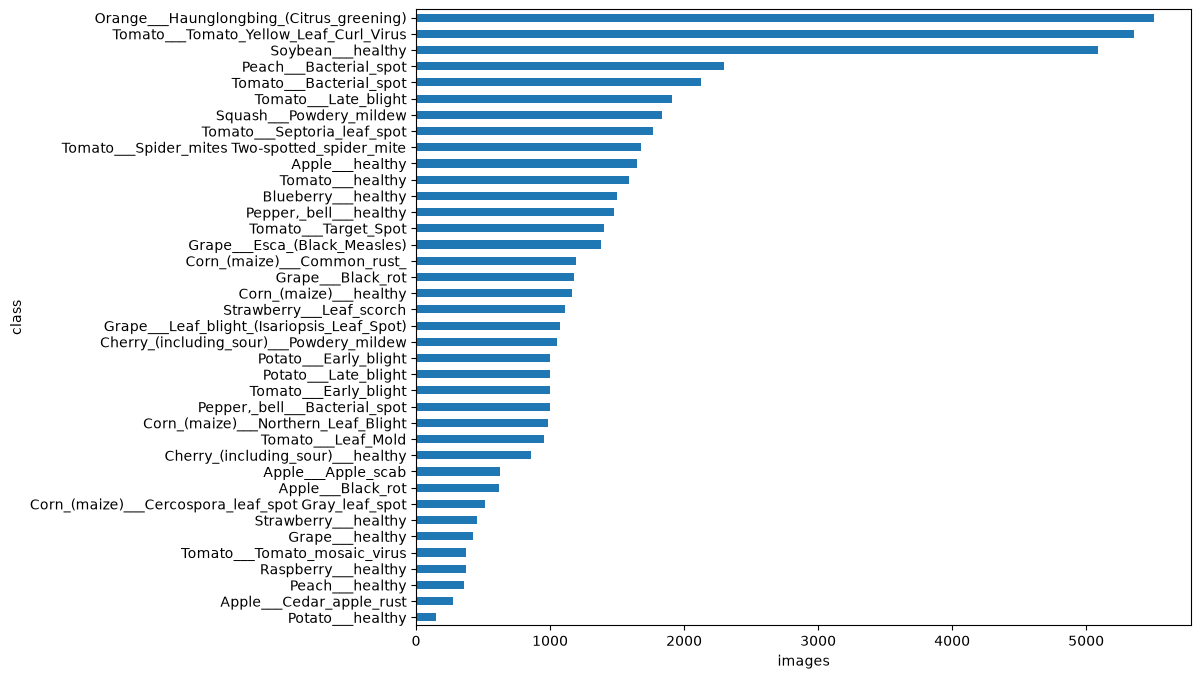

In [18]:
# EDA

# 1. class distribution
c=raw_df["class"].value_counts().sort_values()
c.plot.barh(figsize=(10,8))
plt.xlabel("images")
print(f"imbalance ratio {c.max()/c.min():.1f}:1")
plt.show()


Apple___Apple_scab
Apple___Black_rot
Apple___Cedar_apple_rust
Apple___healthy


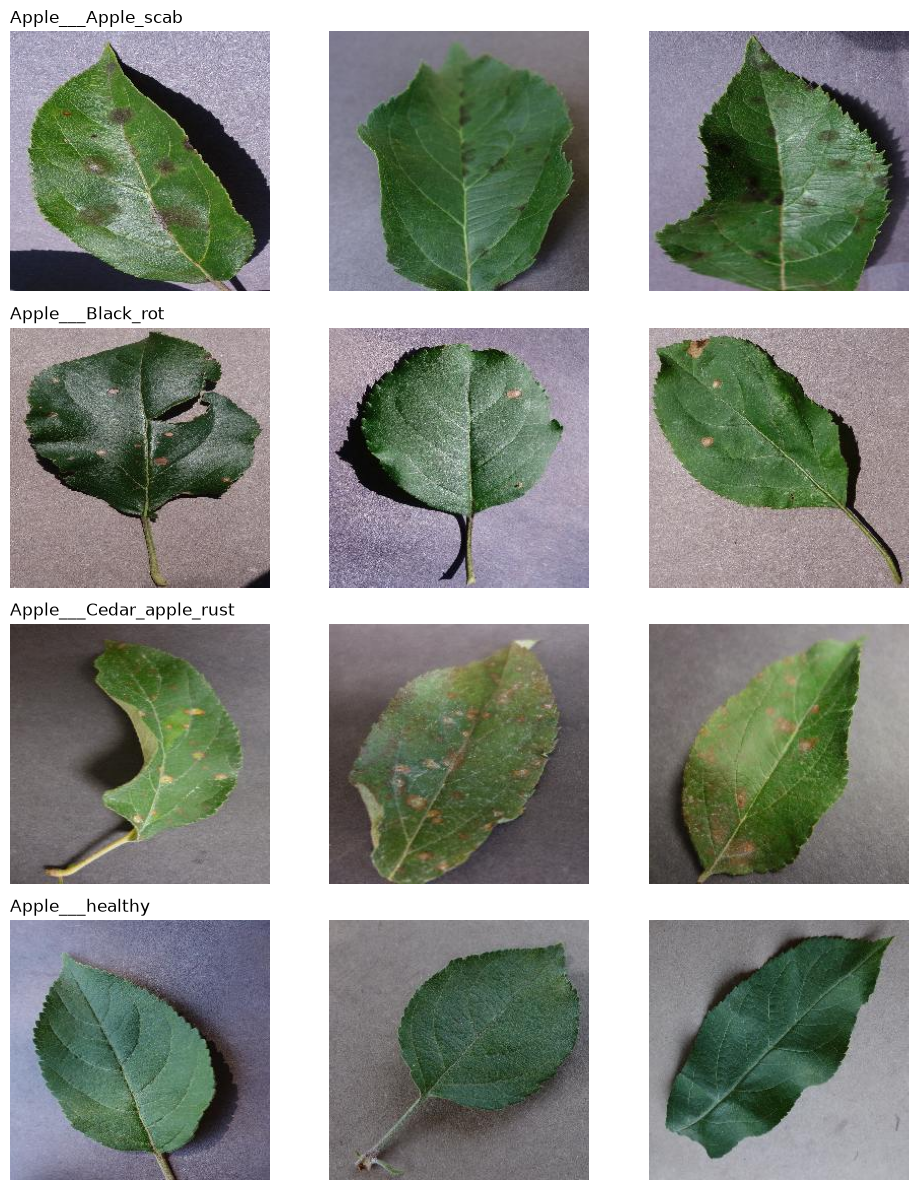

In [6]:
# sample images 

fig, ax=plt.subplots(4,3,figsize=(10,12)) #4 classes * 3 images
for c_ix, cls in enumerate(raw_df["class"].unique()[:4]):
    print(cls)
    for p_ix,p in enumerate(raw_df[raw_df["class"]==cls].path.sample(3, random_state=1)):
        ax[c_ix, p_ix].imshow(Image.open(p))
        ax[c_ix, p_ix].axis('off')
    ax[c_ix, 0].set_title(cls, loc='left')
plt.tight_layout()
plt.show()


/Users/dhvaniraval/.cache/kagglehub/datasets/abdallahalidev/plantvillage-dataset/versions/3/plantvillage dataset/color/Apple___Apple_scab/00075aa8-d81a-4184-8541-b692b78d398a___FREC_Scab 3335.JPG (256, 256) RGB
(256, 256, 3) uint8 0 226 120.23605346679688


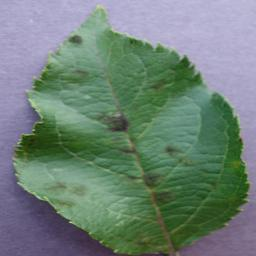

In [ ]:
import numpy as np
p = raw_df.path.iloc[0]
im = Image.open(p)
print(p, im.size, im.mode)
a = np.asarray(im)
print(a.shape, a.dtype, a.min(), a.max(), a.mean())
im

In [ ]:
# check duplicates - we have 21 duplicate images 
raw_df["hash_key"]=[hashlib.md5(open(p,'rb').read()).hexdigest() for p in raw_df.path]
print(f"duplicate images {raw_df.hash_key.duplicated().sum()}")


duplicate images 21


In [25]:
raw_df.shape

(54305, 4)

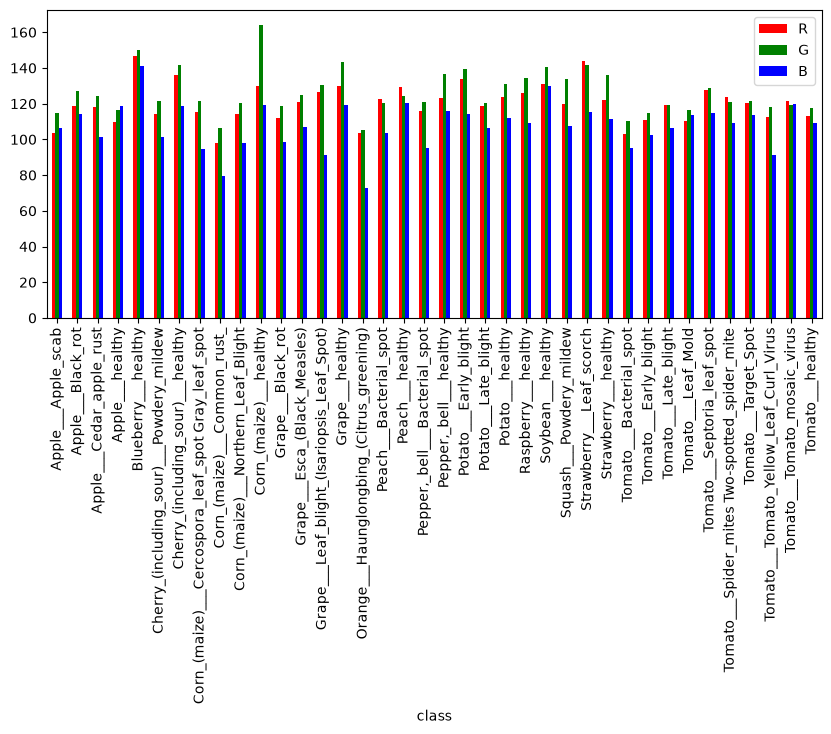

In [9]:
# pixel stats per label

import numpy as np
s=raw_df.groupby('class').head(50)
stats=[(l, *np.asarray(Image.open(p).convert('RGB').resize((64,64)), dtype=float).mean((0,1)))for p, l in zip(s.path, s["class"])]


stat_df=pd.DataFrame(stats,columns=['class', 'R', 'G', 'B']).groupby('class').mean()
stat_df.plot.bar(color=['r', 'g', 'b'], figsize=(10, 4))
plt.show()

In [18]:
# bias

def outline_mean(p, b=12):
    a = np.asarray(Image.open(p).convert('RGB'), dtype=float)
    m = np.ones(a.shape[:2], bool); m[b:-b, b:-b] = False
    return a[m].mean(0)
bm = pd.DataFrame([outline_mean(p) for p in s.path], columns=['R', 'G', 'B']); bm['class'] = s['class'].values
bm.groupby('class').mean().round(0)

,R,G,B
class,,,
Apple___Apple_scab,124.0,121.0,138.0
Apple___Black_rot,152.0,141.0,154.0
Apple___Cedar_apple_rust,131.0,125.0,124.0
Apple___healthy,138.0,135.0,149.0
Blueberry___healthy,177.0,169.0,181.0
Cherry_(including_sour)___Powdery_mildew,130.0,123.0,125.0
Cherry_(including_sour)___healthy,175.0,159.0,158.0
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,119.0,121.0,106.0
Corn_(maize)___Common_rust_,52.0,57.0,43.0


In [ ]:
# preprocessing that will is must for this use case,  not doing a lot due to time limit 

# 1. remove duplicates 
# we have duplicate images inside the same class, so we can keep only one drop the extra

dup=raw_df[raw_df.duplicated("hash_key",keep=False)]
print(f'{len(dup)} files in {dup.hash_key.nunique()} duplicate groups')
conflict=dup.groupby('hash_key')['class'].nunique()
print('groups with conflicting classes:', (conflict > 1).sum())

before = len(raw_df)
raw_df = raw_df.drop_duplicates('hash_key', keep='first').reset_index(drop=True)
print(f'removed {before - len(raw_df)} duplicate files')

# test - no duplicate images anymore
# raw_df["hash_key"]=[hashlib.md5(open(p,'rb').read()).hexdigest() for p in raw_df.path]
# print(f"duplicate images {raw_df.hash_key.duplicated().sum()}")

42 files in 21 duplicate groups
hash_key
0e0dcd876f5b32cac9da836b2e783d91    1
161940bd6e73cf648974cc7213cffb8f    1
1d87a50fa691cef6f476b20bb48cfaf8    1
2e53ad1ec3f810e2ff4c83400dc69ec9    1
32cb22521edc69a5503a6749446dd522    1
3b227920ba50ce0a4602b258f624e935    1
3dab5eb1192b5c43fd3015490cf0b18f    1
48f5d94e58351849b9f219c674323d58    1
4b73700b68ce8704f6b4549a2846dede    1
4bab4aa40d89e19ed72d8b8d501b1db8    1
5bdbdc7333be3ab35ef81ec17ce14816    1
61cabcbf7a2412e44ce0bcee3c384a25    1
68f05a541bf01c0fcfbc7f9445f8a147    1
6e48e89e89da343b6b90ccda5b18d698    1
8bbefab9461168ef9946618480d2f0ad    1
926f8ebcfc60d44649018c5154c8fcec    1
bf12be065849d781b7da2e79091b1072    1
c1b24c8caaa06e756560a83d7358579e    1
ca06650efa30a3f6731df694f07b4690    1
ea0a44df2e4e44c6ccacc31f067a6284    1
fb72d1f9dbd2af9a9ee3fc3421ecf6a4    1
Name: class, dtype: int64
groups with conflicting classes: 0
0
removed 21 duplicate files


In [43]:
# select 12 classes randomly from color folder 

random.seed(42)

all_classes = sorted(raw_df['class'].unique())
selected = sorted(random.sample(all_classes, 12))

raw_df2 = raw_df[raw_df['class'].isin(selected)].reset_index(drop=True)
raw_df2['label'] = raw_df2['class'].map({c: i for i, c in enumerate(selected)})

print(selected)
print(raw_df2['class'].value_counts())

classes=sorted(selected)

['Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___healthy', 'Potato___Late_blight', 'Raspberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus']
class
Orange___Haunglongbing_(Citrus_greening)              5507
Tomato___Tomato_Yellow_Leaf_Curl_Virus                5357
Tomato___Bacterial_spot                               2127
Corn_(maize)___Common_rust_                           1192
Potato___Late_blight                                  1000
Cherry_(including_sour)___healthy                      854
Apple___Black_rot                                      621
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     513
Grape___healthy                                        423
Raspberry___healthy                                    371
Peach___healthy                   

In [ ]:
# we will have total 18600 records for the training
raw_df2.shape #18600, 4 - 

(18600, 4)

In [ ]:
# Stratified split (~70/20/10). before augmentation

from sklearn.model_selection import train_test_split
train_df, temp = train_test_split(raw_df2, test_size=0.30, stratify=raw_df2.label, random_state=42)
val_df, test_df = train_test_split(temp, test_size=0.35, stratify=temp.label, random_state=42)

In [40]:
print(raw_df2.shape, train_df.shape, val_df.shape, test_df.shape) #(13020, 4) (3738, 4) (1842, 4)

(18600, 4) (13020, 4) (3627, 4) (1953, 4)


In [ ]:
# Augmentation

# resizing, horizontal flipping, vertical flipping, rotating, scaling - For training data
# resizing, scaling - For validation and test data

from torchvision import transforms as T
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225] # standard ImageNet values 
aug_train_df = T.Compose(
    [T.RandomResizedCrop(224, scale=(0.7, 1.0)), 
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.RandomRotation(30), 
    T.ToTensor(),
    T.Normalize(mean, std)])
aug_eval_df = T.Compose([
    T.Resize((224, 224)), 
    T.ToTensor(), 
    T.Normalize(mean, std)])

In [ ]:
# Handle imbalanced classes  

import torch, torch.nn as nn
n = train_df.label.value_counts().sort_index().values
w = (len(train_df) / (len(classes) * n)) ** 0.5
criterion = nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32))